# SafeSight · Notebook v2 (YOLO11s): a PPE detector that has to beat the app's current models

**Why a v2.** Notebook C (`checksafetycv.ipynb`, YOLO11s on Construction Site Safety) did not beat the two
pretrained models the app already runs:

| Test | v1 (CSS YOLO11s) | Current app |
|---|---|---|
| CSS own test set, mAP50 / mAP50-95 | 0.881 / 0.638 | 0.897 / 0.684 |
| Construction-PPE (never seen), person/helmet/vest | 0.610 / 0.236 | 0.733 / 0.312 |

Its training data are Roboflow mosaics (four photos per image, black cut-outs), so it learned collages, the same photos
ended up in both train and test, and its per-worker check never ran.

**What v2 changes**
1. **Real photos from four sources, one class list.** Construction-PPE (Ultralytics, construction sites), SH17 (8k
   industrial photos with every PPE class), Hard Hat Workers (5k, helmets) and, for training only, CSS.
2. **Frozen test sets that no model has trained on.** Construction-PPE's official val split (the headline), SH17's
   official val split and a fixed 15% of Hard Hat Workers. Near-duplicates of test images are removed from
   training, and each test set is scored only on the classes it labels.
3. **Missing labels filled in.** A teacher trained on the fully labelled sets (Construction-PPE + SH17) labels the
   classes the other sets don't annotate (e.g. vests in Hard Hat Workers), so unlabelled PPE isn't learned as
   background.
4. **The app's real metric.** Per-worker helmet / vest / gloves / boots / goggles accuracy with the app's own pipeline
   (`ppe_core` + pose model). Ground truth comes from Construction-PPE's explicit `no_helmet`, `no_vest`, … labels.
5. **Clear training rules** (see below), so the run stops at the right time and fits in one Kaggle session.

Classes: `person, helmet, vest, gloves, boots, goggles, mask, earmuffs`. The app maps these names itself.

### Training rules
| Rule | Setting |
|---|---|
| Model | YOLO11s (same architecture as v1, so any gain comes from the data and training) |
| Hardware | both T4s (`GPU T4 x2`, DDP), 16 images per GPU; falls back to one GPU if DDP fails |
| Model selection | `best.pt` = the epoch with the highest **validation mAP50-95** (Construction-PPE + SH17 val, never test) |
| Early stopping | stop when validation mAP50-95 hasn't improved for `PATIENCE` epochs (teacher 20, final model 30) |
| Time cap | at most `TEACHER_HOURS` / `STUDENT_HOURS`, and never past `SESSION_HOURS` (Kaggle stops at 12 h) |
| Schedule | AdamW (Ultralytics auto), cosine learning-rate decay, 3 warm-up epochs, mosaic off for the last 10 epochs |
| Confidence threshold | the one with the best F1 on the validation images; use it when registering the model in the app |
| Verdict | replace the current models only if v2 is better on the Construction-PPE test mAP50-95 **and** no worse on per-worker helmet+vest accuracy |

### Kaggle setup
* **Settings:** Accelerator *GPU T4 x2*; Internet *On*.
* **Add Input:**
  * `jeswintobias/construction-ppe-2026-11` (a frozen copy of Construction-PPE, so the test set never changes;
    without it the notebook downloads the current version from GitHub)
  * `mugheesahmad/sh17-dataset-for-ppe-detection` (SH17)
  * `andrewmvd/hard-hat-detection` (Hard Hat Workers)
  * `snehilsanyal/construction-site-safety-image-dataset-roboflow` (CSS: training only)
  * `jeswintobias/safesight-app`: the app's `ppe_core/` folder, its `models/*.onnx` (the baseline and the
    per-worker check use exactly these) and `weights/*.pt` (YOLO base weights, so nothing is downloaded from GitHub).
  * The output of `jeswintobias/checksafetycv` (v1), to include it in the comparison.
* **Do a dry run first:** set `SMOKE = True` in the next cell and *Run All* (about 10 min, works on CPU). It checks
  every input and every step on a few images.
* **Then the real run:** set `SMOKE = False`, then **Save Version → Save & Run All (Commit)**. With the defaults it
  takes about 7 h.

Outputs in `/kaggle/working`: `safesight_v2_yolo11s.onnx` and `results/` (comparison tables, per-worker accuracy,
the frozen split list, `summary.json`, and notes to paste into the app's *Models* page).

Licenses: SH17 is CC BY-NC-SA 4.0 (non-commercial), and so is a model trained on it. Construction-PPE and CSS are
CC BY 4.0. Hard Hat Workers is public domain.

In [1]:
# ---------------- configuration ----------------
import os, sys, re, json, math, random, shutil, time, hashlib, zipfile, subprocess, collections, urllib.request
from pathlib import Path

SMOKE = False             # True = dry run on a few images (any hardware, ~10 min): checks inputs and every step
SMOKE = SMOKE or os.environ.get("SAFESIGHT_SMOKE") == "1"

CLASSES = ["person", "helmet", "vest", "gloves", "boots", "goggles", "mask", "earmuffs"]
MODEL = "yolo11s.pt"      # COCO-pretrained start; n/s keep the ONNX under the app's 50 MB limit
IMGSZ = 640               # 800 helps small PPE (gloves, goggles) but costs ~1.5x training and app CPU time
BATCH_PER_GPU = 16        # total batch = 16 x number of GPUs (32 on T4 x2)
SEED = 42
TEACHER_HOURS = 1.5       # stage 1 cap: teacher on the fully labelled sets (Construction-PPE + SH17)
STUDENT_HOURS = 5.0       # stage 2 cap: final model on every set, starting from the teacher
PATIENCE = {"teacher": 20, "v2": 30}   # early stopping: epochs without a better validation mAP50-95
SESSION_HOURS = 11.3      # Kaggle kills a session at 12 h; training is shortened so everything ends before this
TEACHER_WEIGHTS = None    # path to a teacher best.pt from an earlier run: skips stage 1
PSEUDO_CONF = 0.5         # teacher boxes kept as labels for classes a dataset does not annotate
USE_CSS = True            # Construction Site Safety mosaics: extra training data, never used for val/test
OVERSAMPLE = {"cppe": 3}  # repeat the small construction set so SH17's factory photos don't dominate
MAX_SIDE = 800            # train/val images are resized once to this longest side (SH17 photos are up to 8K)
TEST_SIDE = 1280          # test images keep more detail (the per-worker check measures people in pixels)
GPUS = "all"              # "all" = every GPU (T4 x2 -> DDP), or 1 = a single GPU
REQUIRE = {"sh17": True, "hardhat": True, "app": True}   # stop right away if one of these inputs is missing

SMOKE_N = 12              # images per source and split in a dry run
if SMOKE:
    IMGSZ, BATCH_PER_GPU, MAX_SIDE, TEST_SIDE = 320, 4, 640, 640
T_START = time.time()

ON_KAGGLE = Path("/kaggle/input").exists()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path(os.environ.get("WORK_DIR", "work")).resolve()
INPUT = Path("/kaggle/input") if ON_KAGGLE else Path(os.environ.get("INPUT_DIR", "inputs")).resolve()
SCRATCH = Path("/tmp/safesight") if ON_KAGGLE else WORK / "scratch"   # resized images etc.: large, not kept
RAW, IMG, RES = SCRATCH / "raw", SCRATCH / "images", WORK / "results"
for d in (RAW, IMG, RES):
    d.mkdir(parents=True, exist_ok=True)
CID = {c: i for i, c in enumerate(CLASSES)}
random.seed(SEED)
print("DRY RUN (SMOKE)" if SMOKE else "full run", "| classes:", CLASSES)

full run | classes: ['person', 'helmet', 'vest', 'gloves', 'boots', 'goggles', 'mask', 'earmuffs']


In [2]:
# Pin the Ultralytics version this notebook was tested with
if ON_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "ultralytics==8.4.208", "imagehash", "onnx",
                    "onnxslim", "onnxruntime"], check=True)

In [3]:
import numpy as np, pandas as pd, yaml, torch, torchvision, imagehash
import matplotlib.pyplot as plt, matplotlib.patches as patches
import xml.etree.ElementTree as ET
from concurrent.futures import ThreadPoolExecutor
from PIL import Image, ImageOps
from ultralytics import YOLO
try:
    from IPython.display import display
except ImportError:
    display = print

N_GPU = torch.cuda.device_count() if GPUS == "all" else min(int(GPUS), torch.cuda.device_count())
DEVICE = list(range(N_GPU)) if N_GPU > 1 else (0 if N_GPU == 1 else "cpu")   # a list = DDP over those GPUs
BATCH = BATCH_PER_GPU * max(N_GPU, 1)
PRED_DEVICE = 0 if N_GPU else "cpu"   # prediction and evaluation use one GPU
WORKERS = min(4, os.cpu_count() or 1) if ON_KAGGLE else 0
_trapz = getattr(np, "trapezoid", None) or np.trapz
print("torch", torch.__version__, "| GPUs:", [torch.cuda.get_device_name(i) for i in range(N_GPU)] or "none (CPU)",
      "| training device:", DEVICE, "| batch:", BATCH)

def hours_left():
    return SESSION_HOURS - (time.time() - T_START) / 3600

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
torch 2.11.0+cu130 | GPUs: ['Tesla T4', 'Tesla T4'] | training device: [0, 1] | batch: 32


## 1 · Inputs
Finds every dataset and stops right away if a required one is missing, before any GPU time is spent.

In [4]:
def download(url, dest, tries=6):
    """Download with retries: GitHub sometimes answers 504 for a minute or two."""
    dest = Path(dest)
    for k in range(tries):
        if dest.exists():
            break
        try:
            print("downloading", url)
            tmp = dest.with_name(dest.name + ".part")
            urllib.request.urlretrieve(url, tmp)
            tmp.rename(dest)
        except Exception as e:
            if k == tries - 1:
                raise
            print(f"  failed ({e}); retrying in {30 * (k + 1)} s")
            time.sleep(30 * (k + 1))
    return dest

def find(pattern, ok=lambda p: True):
    for p in (sorted(INPUT.glob(pattern)) if INPUT.exists() else []):
        if ok(p):
            return p
    return None

CPPE_URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip"
CPPE_FROZEN = "construction-ppe-2026-11"   # Kaggle dataset jeswintobias/construction-ppe-2026-11

def cppe_root():
    """The frozen Kaggle copy if attached (looked up by name: v1's output holds an older download of the
    same dataset that must not be picked up), otherwise the current version from GitHub."""
    if os.environ.get("CPPE_DIR"):
        return Path(os.environ["CPPE_DIR"])
    hit = find(f"**/{CPPE_FROZEN}/**/data.yaml")
    if hit:
        return hit.parent
    print(f"{CPPE_FROZEN} is not attached: using the current Construction-PPE from GitHub (test set may differ)")
    out = RAW / "construction-ppe"
    if not any(out.rglob("data.yaml")):
        with zipfile.ZipFile(download(CPPE_URL, RAW / "construction-ppe.zip")) as z:
            z.extractall(out)
    return next(out.rglob("data.yaml")).parent   # newer zips have a top-level folder, older ones don't

def parent(p, up=1):
    return None if p is None else p.parents[up - 1]

ROOTS = {
    "cppe": cppe_root(),
    "sh17": parent(find("**/train_files.txt", lambda p: (p.parent / "images").is_dir() and (p.parent / "labels").is_dir())),
    "hardhat": parent(find("**/annotations/*.xml", lambda p: (p.parent.parent / "images").is_dir()), 2),
    "css": None,
}
if USE_CSS:   # Kaggle mounts it at /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow
    known = INPUT / "datasets" / "snehilsanyal" / "construction-site-safety-image-dataset-roboflow" / "css-data"
    ROOTS["css"] = known if known.is_dir() else find("**/css-data", lambda p: p.is_dir())

# the app: its ppe_core package (per-worker check) and the ONNX models it runs today
hit = find("**/ppe_core/__init__.py")
APP = parent(hit, 2)
if APP is None and (Path.cwd().parent / "backend" / "ppe_core").is_dir():   # running inside the repo
    APP = Path.cwd().parent / "backend"
APP_FILES = ("construction-safety-yolov8n.onnx", "yolo8s.onnx", "yolo11n-pose.onnx")
APP_MODELS = {}
for n in APP_FILES:
    p = next(iter(sorted(APP.rglob(n))), None) if APP else None
    p = p or find(f"**/{n}")
    if p:
        APP_MODELS[n] = p
V1_ONNX = find("**/safesight_css_*.onnx")   # notebook C's model, if its output was added

# Base weights from the safesight-app input (weights/*.pt) when present, so nothing has to come from GitHub
# (GitHub downloads have failed from Kaggle with HTTP 504). Otherwise Ultralytics downloads them as usual.
from ultralytics.utils import SETTINGS
LOCAL_PT = {p.name: p for p in sorted(APP.rglob("*.pt"))} if APP else {}
MODEL_PATH = str(LOCAL_PT.get(MODEL, MODEL))
for n in ("yolo26n.pt", "yolo11n.pt"):   # what Ultralytics' AMP self-check loads on GPU
    if n in LOCAL_PT and not (Path(SETTINGS["weights_dir"]) / n).exists():
        Path(SETTINGS["weights_dir"]).mkdir(parents=True, exist_ok=True)
        shutil.copy(LOCAL_PT[n], Path(SETTINGS["weights_dir"]) / n)
print(f"{'base weights':26s} {MODEL_PATH}")

TITLES = {"cppe": "Construction-PPE", "sh17": "SH17", "hardhat": "Hard Hat Workers", "css": "Construction Site Safety"}
for k, v in ROOTS.items():
    print(f"{TITLES[k]:26s} {v or 'not found'}")
print(f"{'app (ppe_core + models)':26s} {APP or 'not found'} | models: {sorted(APP_MODELS) or 'none'}")
print(f"{'v1 model (optional)':26s} {V1_ONNX or 'not attached'}")

need = {"sh17": ROOTS["sh17"], "hardhat": ROOTS["hardhat"], "app": APP if len(APP_MODELS) == len(APP_FILES) else None}
missing = [k for k, v in need.items() if REQUIRE[k] and v is None]
if missing:
    raise RuntimeError(f"Missing inputs: {missing}. Add them under 'Add Input' (see the setup notes at the top) "
                       "or set REQUIRE[...] = False to run without them.")
if USE_CSS and ROOTS["css"] is None:
    print("CSS not attached: training without it")
    USE_CSS = False

base weights               /kaggle/input/datasets/jeswintobias/safesight-app/weights/yolo11s.pt
Construction-PPE           /kaggle/input/construction-ppe-2026-11/construction-ppe
SH17                       /kaggle/input/datasets/mugheesahmad/sh17-dataset-for-ppe-detection
Hard Hat Workers           /kaggle/input/datasets/andrewmvd/hard-hat-detection
Construction Site Safety   /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data
app (ppe_core + models)    /kaggle/input/datasets/jeswintobias/safesight-app | models: ['construction-safety-yolov8n.onnx', 'yolo11n-pose.onnx', 'yolo8s.onnx']
v1 model (optional)        /kaggle/input/checksafetycv/safesight_css_yolo11s.onnx


## 2 · Data: one class list, frozen splits, no near-duplicates across splits

| Source | Train | Val (model selection) | Test (frozen) | Labels these classes |
|---|---|---|---|---|
| Construction-PPE | 85% of its train split | 15% of its train split | its official val split (or test, if present) | person, helmet, vest, gloves, boots, goggles (+ `no_*` negatives) |
| SH17 | 90% of `train_files.txt` | 10% of `train_files.txt` | `val_files.txt` | all 8 |
| Hard Hat Workers | 85% | – | 15% | helmet |
| CSS (optional) | all | – | – | person, helmet, vest, mask |

The splits come from a hash of each file name, so every run gets exactly the same ones. SH17's `shoes` and
`glasses` are mapped to `boots` and `goggles`, as the app already does with the SH17 model.

In [5]:
def norm(name):
    return re.sub(r"[^a-z]", "", str(name).lower())

POS = {"person": "person", "helmet": "helmet", "hardhat": "helmet", "vest": "vest", "safetyvest": "vest",
       "gloves": "gloves", "boots": "boots", "shoes": "boots", "goggles": "goggles", "glasses": "goggles",
       "mask": "mask", "facemask": "mask", "facemaskmedical": "mask", "earmufs": "earmuffs", "earmuffs": "earmuffs"}
NEG = {"nohelmet": "helmet", "nohardhat": "helmet", "novest": "vest", "nosafetyvest": "vest", "nogloves": "gloves",
       "noboots": "boots", "nogoggle": "goggles", "nogoggles": "goggles", "nomask": "mask"}
# classes each source annotates on every image; the rest are filled in by the teacher (section 5)
LABELED = {"cppe": {"person", "helmet", "vest", "gloves", "boots", "goggles"}, "sh17": set(CLASSES),
           "hardhat": {"helmet"}, "css": {"person", "helmet", "vest", "mask"}}
SH17_NAMES = ["person", "ear", "ear-mufs", "face", "face-guard", "face-mask", "foot", "tool", "glasses", "gloves",
              "helmet", "hands", "head", "medical-suit", "shoes", "safety-suit", "safety-vest"]
CSS_NAMES = ["Hardhat", "Mask", "NO-Hardhat", "NO-Mask", "NO-Safety Vest", "Person", "Safety Cone", "Safety Vest",
             "machinery", "vehicle"]
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def auto_map(names):
    """model class name -> our class, the way the app maps names (negatives like NO-Hardhat are skipped)."""
    return {raw: POS[norm(raw)] for raw in names.values() if norm(raw) in POS}

def bucket(key):   # stable number in [0, 1) per file: the splits never change between runs
    return int(hashlib.md5(key.encode()).hexdigest()[:8], 16) / 2**32

def names_dict(names):
    return dict(enumerate(names)) if isinstance(names, list) else {int(k): v for k, v in names.items()}

def read_yolo(lp, names):
    """YOLO label file -> positives and negatives as (class, x1, y1, x2, y2), normalised to 0..1."""
    pos, neg = [], []
    if not lp.exists():
        return pos, neg
    for line in lp.read_text(encoding="utf-8", errors="ignore").splitlines():
        p = line.split()
        if len(p) < 5:
            continue
        try:
            k, v = int(float(p[0])), list(map(float, p[1:]))
        except ValueError:
            continue
        if len(v) == 4:
            box = (v[0] - v[2] / 2, v[1] - v[3] / 2, v[0] + v[2] / 2, v[1] + v[3] / 2)
        else:   # polygon -> bounding box
            box = (min(v[0::2]), min(v[1::2]), max(v[0::2]), max(v[1::2]))
        n = norm(names.get(k, ""))
        if n in POS:
            pos.append((POS[n], *box))
        elif n in NEG:
            neg.append((NEG[n], *box))
    return pos, neg

def record(src, image, key, split, pos, neg=()):
    return dict(src=src, image=Path(image), key=f"{src}/{key}", split=split,
                boxes=[b for b in pos if b[0] in LABELED[src]], neg=list(neg), pseudo=[])

def pmap(fn, items, workers=16):
    """Parallel map for file reads: Kaggle's input disk has high latency, so threads speed loading up a lot."""
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(fn, items))

def load_cppe(root):
    names = names_dict(yaml.safe_load(open(root / "data.yaml", encoding="utf-8"))["names"])
    subs = [s for s in ("train", "val", "test") if (root / "images" / s).is_dir()]
    assert subs, f"no images/train|val|test under {root}"
    todo = []
    for s in subs:
        for ip in sorted(p for p in (root / "images" / s).rglob("*") if p.suffix.lower() in IMG_EXT):
            rel = ip.relative_to(root / "images")
            if s == "test" or (s == "val" and "test" not in subs):
                split = "test"
            elif s == "val":
                split = "val"
            else:
                split = "val" if bucket(str(rel)) < 0.15 else "train"
            todo.append((ip, rel, split))
    return pmap(lambda t: record("cppe", t[0], t[1], t[2],
                                 *read_yolo((root / "labels" / t[1]).with_suffix(".txt"), names)), todo)

def load_sh17(root):
    names = dict(enumerate(SH17_NAMES))
    lists = {s: {Path(l.strip()).name for l in (root / f).read_text().splitlines() if l.strip()}
             for s, f in (("train", "train_files.txt"), ("test", "val_files.txt"))}
    todo = []
    for ip in sorted(p for p in (root / "images").iterdir() if p.suffix.lower() in IMG_EXT):
        if ip.name in lists["test"]:
            todo.append((ip, "test"))
        elif ip.name in lists["train"]:
            todo.append((ip, "val" if bucket(ip.name) < 0.1 else "train"))
    return pmap(lambda t: record("sh17", t[0], t[0].name, t[1],
                                 *read_yolo(root / "labels" / (t[0].stem + ".txt"), names)), todo)

def load_hardhat(root):
    images = {p.stem: p for p in (root / "images").iterdir() if p.suffix.lower() in IMG_EXT}
    pairs = [(xp, images[xp.stem]) for xp in sorted((root / "annotations").glob("*.xml")) if xp.stem in images]
    return pmap(lambda t: hardhat_record(*t), pairs)

def hardhat_record(xp, ip):
    t = ET.parse(xp).getroot()
    try:
        w, h = (float(t.find("size").findtext(k)) for k in ("width", "height"))
        assert w > 0 and h > 0
    except Exception:
        w, h = Image.open(ip).size
    pos = []
    for o in t.findall("object"):
        n, b = norm(o.findtext("name")), o.find("bndbox")
        if n in POS and b is not None:
            x1, y1, x2, y2 = (float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))
            pos.append((POS[n], x1 / w, y1 / h, x2 / w, y2 / h))
    return record("hardhat", ip, ip.name, "test" if bucket(ip.name) < 0.15 else "train", pos)

def load_css(root):
    yml = next(iter(sorted(root.rglob("data.yaml"))), None)
    names = names_dict(yaml.safe_load(open(yml, encoding="utf-8"))["names"] if yml else CSS_NAMES)
    todo = []
    for s in ("train", "valid", "test"):
        d = root / s / "images"
        if d.is_dir():
            todo += [(s, d, ip) for ip in sorted(p for p in d.rglob("*") if p.suffix.lower() in IMG_EXT)]
    def one(t):
        s, d, ip = t
        rel = ip.relative_to(d)
        return record("css", ip, f"{s}/{rel}", "train", *read_yolo((root / s / "labels" / rel).with_suffix(".txt"), names))
    return pmap(one, todo)

LOADERS = {"cppe": load_cppe, "sh17": load_sh17, "hardhat": load_hardhat, "css": load_css}
records = []
for src, root in ROOTS.items():
    if root is not None and (src != "css" or USE_CSS):
        recs = LOADERS[src](root)
        if SMOKE:   # a few images per split
            by = collections.defaultdict(list)
            for r in recs:
                by[r["split"]].append(r)
            recs = [r for rs in by.values() for r in sorted(rs, key=lambda r: bucket(r["key"]))[:SMOKE_N]]
        print(f"{TITLES[src]:26s} {len(recs):6d} images")
        records += recs

Construction-PPE             1000 images
SH17                         8099 images
Hard Hat Workers             5000 images
Construction Site Safety     2801 images


In [6]:
# ---- resize every image once (EXIF orientation applied, like OpenCV does in training) + perceptual hash ----
def prepare(r):
    dst = IMG / f"{r['src']}_{hashlib.md5(r['key'].encode()).hexdigest()[:12]}.jpg"
    side = TEST_SIDE if r["split"] == "test" else MAX_SIDE
    try:
        if dst.exists():
            im = Image.open(dst).convert("RGB")
        else:
            im = Image.open(r["image"])
            im.draft("RGB", (side, side))   # fast JPEG decode at reduced size
            im = ImageOps.exif_transpose(im).convert("RGB")
            im.thumbnail((side, side), Image.Resampling.LANCZOS)
            im.save(dst, quality=92)
        return str(dst), im.size, int(str(imagehash.phash(im)), 16)
    except Exception as e:
        print("skipping unreadable image", r["image"], e)
        return None, None, None

t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    for r, (path, size, h) in zip(records, ex.map(prepare, records)):
        r["path"], r["phash"] = path, h
        r["w"], r["h"] = size or (0, 0)
print(f"prepared {len(records)} images in {(time.time() - t0) / 60:.1f} min")

# ---- drop near-duplicates (Hamming distance <= 4); test images win over val, val over train ----
POP = np.array([bin(i).count("1") for i in range(256)], np.uint8)
order = sorted(range(len(records)), key=lambda i: ("test", "val", "train").index(records[i]["split"]))
kept_h, kept_i, dropped = np.zeros(len(records), np.uint64), [], collections.Counter()
for i in order:
    r = records[i]
    r["keep"] = r["path"] is not None
    if not r["keep"]:
        continue
    if kept_i:
        d = POP[(kept_h[:len(kept_i)] ^ np.uint64(r["phash"])).view(np.uint8)].reshape(-1, 8).sum(1)
        hit = np.flatnonzero(d <= 4)
        if len(hit):
            r["keep"] = False
            dropped[(r["src"], r["split"], "of " + records[kept_i[hit[0]]]["split"])] += 1
            continue
    kept_h[len(kept_i)] = np.uint64(r["phash"])
    kept_i.append(i)
records = [r for r in records if r["keep"]]
print("near-duplicates removed:", dict(dropped) or "none")

pd.DataFrame([{"source": r["src"], "file": r["key"].split("/", 1)[1], "split": r["split"]} for r in records]
             ).to_csv(RES / "frozen_splits.csv", index=False)
stats = pd.DataFrame([{"source": TITLES[r["src"]], "split": r["split"], "images": 1,
                       **collections.Counter(b[0] for b in r["boxes"])} for r in records])
stats = stats.groupby(["source", "split"]).sum().reindex(columns=["images"] + CLASSES).fillna(0).astype(int)
display(stats); stats.to_csv(RES / "dataset_stats.csv")

prepared 16900 images in 14.0 min
near-duplicates removed: {('hardhat', 'test', 'of test'): 7, ('sh17', 'train', 'of train'): 4, ('sh17', 'train', 'of test'): 3, ('hardhat', 'train', 'of test'): 29, ('hardhat', 'train', 'of train'): 57, ('css', 'train', 'of train'): 9}


images  person  helmet  vest  gloves  boots  \
source                   split                                                
Construction Site Safety train    2792    9833    3300  3131       0      0   
Construction-PPE         test      200     481     294   340     381    481   
                         train     680    1673    1101  1251    1337   1724   
                         val       120     289     181   225     211    279   
Hard Hat Workers         test      753       0    2851     0       0      0   
                         train    4154       0   15787     0       0      0   
SH17                     test     1620    2734     154    97     529    956   
                         train    5790    9927     676   387    1991   3179   
                         val       682    1132      96    45     269    415   

                                goggles  mask  earmuffs  
source                   split                           
Construction Site Safety train        0  1700         0  
Construction-PPE         test       139     0         0  
                         train      521     0         0  
                         val         91     0         0  
Hard Hat Workers         test         0     0         0  
                         train        0     0         0  
SH17                     test       398   151        49  
                         train     1374   458       235  
                         val        171    61        33

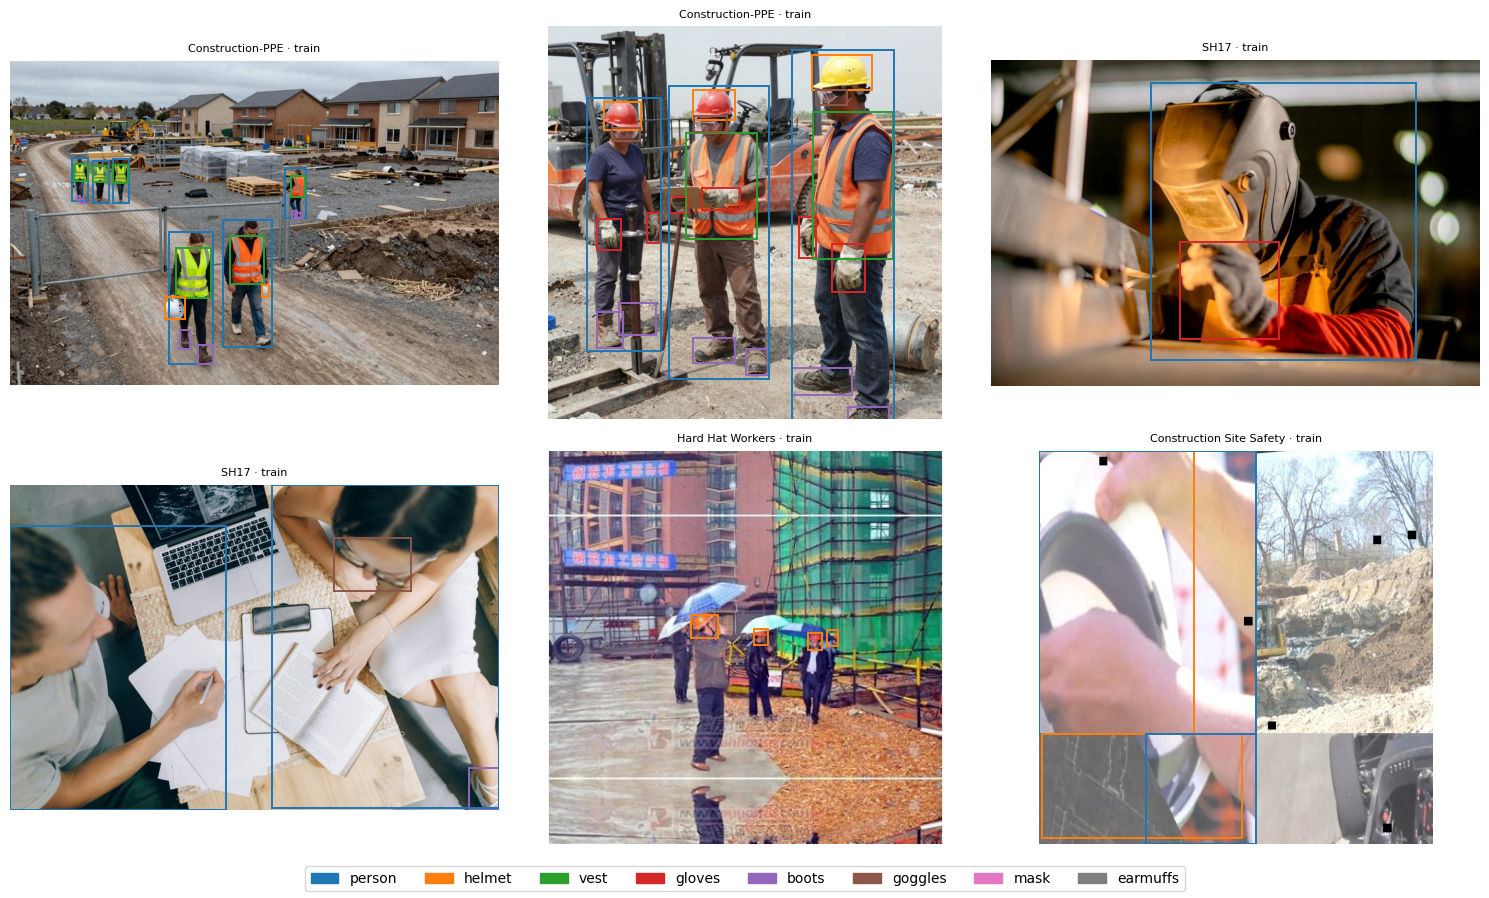

In [7]:
COLORS = {c: plt.cm.tab10(i) for i, c in enumerate(CLASSES)}
LEGEND = [patches.Patch(color=COLORS[c], label=c) for c in CLASSES]

def box_px(r, b):
    return b[1] * r["w"], b[2] * r["h"], b[3] * r["w"], b[4] * r["h"]

def show(ax, r, title=None, pred=None):
    """solid = dataset labels, dashed = teacher pseudo-labels, red dotted = model predictions (pixels)"""
    ax.imshow(Image.open(r["path"])); ax.set_title(title or f"{TITLES[r['src']]} · {r['split']}", fontsize=8); ax.axis("off")
    for boxes, ls in ((r["boxes"], "-"), (r["pseudo"], "--")):
        for b in boxes:
            x1, y1, x2, y2 = box_px(r, b)
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.4, ls=ls, color=COLORS[b[0]]))
    for c, s, x1, y1, x2, y2 in (pred or []):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.2, ls=":", color="red"))

def gallery(rs, fname, titles=None, preds=None):
    rs = list(rs)[:6]
    if not rs:
        return
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for k, ax in enumerate(axes.flat):
        if k < len(rs):
            show(ax, rs[k], titles[k] if titles else None, preds[k] if preds else None)
        else:
            ax.axis("off")
    fig.legend(handles=LEGEND, loc="lower center", ncol=len(CLASSES))
    plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig(RES / fname, dpi=80); plt.show()

def pick(pool, plan, seed):
    """a few distinct images per source, e.g. plan = (("cppe", 2), ("sh17", 2))"""
    rng, out = random.Random(seed), []
    for s, k in plan:
        rs = [r for r in pool if r["src"] == s]
        out += rng.sample(rs, min(k, len(rs)))
    return out

gallery(pick([r for r in records if r["split"] == "train"], (("cppe", 2), ("sh17", 2), ("hardhat", 1), ("css", 1)), 1),
        "samples.png")

## 3 · Baseline: what the app runs today, on the frozen test sets
Evaluation helpers, then the two pretrained detectors, alone and merged as the app merges them (class-wise NMS).
AP is COCO-style (IoU 0.50:0.95, 101-point), and each test set is scored only on the classes it labels.

In [8]:
THRS = np.linspace(0.5, 0.95, 10)

def iou_matrix(a, b):
    ix = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    iy = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    inter = ix * iy
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

def ap_per_class(preds, gts, classes):
    """{class: AP at each IoU threshold}. preds {image: [(cls, score, x1, y1, x2, y2)]}, gts {image: [(cls, x1, y1, x2, y2)]}.
    Detections are matched greedily by score to the unmatched ground truth with the highest IoU (COCO)."""
    out = {}
    for c in classes:
        scores, tps, n_gt = [], [], 0
        for img, gt in gts.items():
            g = np.array([b[1:] for b in gt if b[0] == c], float).reshape(-1, 4)
            d = sorted((p for p in preds.get(img, []) if p[0] == c), key=lambda p: -p[1])
            n_gt += len(g)
            if not d:
                continue
            tp = np.zeros((len(d), len(THRS)), bool)
            if len(g):
                iou = iou_matrix(g, np.array([p[2:] for p in d], float))   # (gt, det)
                cand = np.flatnonzero(iou.max(0) >= THRS[0])
                for k, t in enumerate(THRS):
                    used = np.zeros(len(g), bool)
                    for j in cand:
                        m = np.where(used, -1.0, iou[:, j])
                        i = int(m.argmax())
                        if m[i] >= t:
                            used[i], tp[j, k] = True, True
            scores.append(np.array([p[1] for p in d])); tps.append(tp)
        if n_gt == 0:
            continue
        if not scores:
            out[c] = np.zeros(len(THRS)); continue
        tp = np.concatenate(tps)[np.argsort(-np.concatenate(scores), kind="stable")]
        tpc, fpc = np.cumsum(tp, 0), np.cumsum(~tp, 0)
        x, aps = np.linspace(0, 1, 101), []
        for k in range(len(THRS)):
            mrec = np.concatenate([[0.], tpc[:, k] / n_gt, [1.]])
            mpre = np.concatenate([[1.], tpc[:, k] / np.maximum(tpc[:, k] + fpc[:, k], 1e-9), [0.]])
            mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
            aps.append(_trapz(np.interp(x, mrec, mpre), x))
        out[c] = np.array(aps)
    return out

def predict(model, paths, conf=0.001, imgsz=None, cmap=None, batch=16, device=None):
    """{image: [(cls, score, x1, y1, x2, y2)]} in our class names; cmap None = map names like the app does.
    ONNX models run on CPU (device="cpu"), as in the app. Class names are read from the first result: asking an
    ONNX model for .names before predicting would load it on the GPU and make Ultralytics install onnxruntime-gpu."""
    out = {}
    for i in range(0, len(paths), batch):
        chunk = paths[i:i + batch]
        for p, res in zip(chunk, model.predict(chunk, conf=conf, iou=0.6, imgsz=imgsz or IMGSZ,
                                               device=PRED_DEVICE if device is None else device,
                                               verbose=False, max_det=300)):
            cmap = cmap or auto_map(res.names)
            b, s, k = (res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy(), res.boxes.cls.cpu().numpy().astype(int))
            out[p] = [(cmap[res.names[int(kk)]], float(ss), *map(float, bb)) for bb, ss, kk in zip(b, s, k)
                      if res.names[int(kk)] in cmap]
    return out

def merge(*pred_dicts, iou=0.6):
    """Ensemble: class-wise NMS over several models' detections (what the app does with several detectors)."""
    out = {}
    for p in pred_dicts[0]:
        dets = [d for pdict in pred_dicts for d in pdict.get(p, [])]
        if len(dets) > 1:
            keep = torchvision.ops.batched_nms(torch.tensor([d[2:] for d in dets]), torch.tensor([d[1] for d in dets]),
                                               torch.tensor([CID[d[0]] for d in dets]), iou).numpy()
            dets = [dets[k] for k in keep]
        out[p] = dets
    return out

TEST = {s: [r for r in records if r["src"] == s and r["split"] == "test"] for s in ("cppe", "sh17", "hardhat")}
TEST = {s: rs for s, rs in TEST.items() if rs}
TEST_GT = {s: {r["path"]: [(b[0], *box_px(r, b)) for b in r["boxes"]] for r in rs} for s, rs in TEST.items()}
TEST_PATHS = [p for g in TEST_GT.values() for p in g]
TEST_CLASSES = {s: [c for c in CLASSES if c in LABELED[s]] for s in TEST}
SHORT = {"cppe": "CPPE", "sh17": "SH17", "hardhat": "HardHat"}
PRED, APS = {}, {}

def evaluate(name, preds):
    PRED[name] = preds
    APS[name] = {s: ap_per_class(preds, gt, TEST_CLASSES[s]) for s, gt in TEST_GT.items()}

def overview():
    rows = []
    for name, per in APS.items():
        row = {"model": name}
        for s, ap in per.items():
            row[f"{SHORT[s]} mAP50"] = np.mean([v[0] for v in ap.values()]) if ap else np.nan
            row[f"{SHORT[s]} mAP50-95"] = np.mean([v.mean() for v in ap.values()]) if ap else np.nan
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")

def per_class(s, iou50=True):
    return pd.DataFrame({name: {c: (v[0] if iou50 else v.mean()) for c, v in per[s].items()}
                         for name, per in APS.items()}).T

# the app's two detectors exactly as the app runs them: its ONNX files (no downloads; ~10 min on CPU)
APP_ONNX = {"SH17 yolov8s": "yolo8s.onnx", "site-safety yolov8n": "construction-safety-yolov8n.onnx"}
assert all(f in APP_MODELS for f in APP_ONNX.values()), "the baseline needs the safesight-app input (models/*.onnx)"
app_models = {n: YOLO(str(APP_MODELS[f]), task="detect") for n, f in APP_ONNX.items()}
t0 = time.time()
for n, m in app_models.items():
    evaluate(f"app: {n}", predict(m, TEST_PATHS, imgsz=640, device="cpu"))
    print(n, "->", auto_map(m.predictor.model.names))
evaluate("current app (both)", merge(*(PRED[f"app: {n}"] for n in APP_ONNX)))
if V1_ONNX:
    evaluate("v1 (CSS yolo11s)", predict(YOLO(str(V1_ONNX), task="detect"), TEST_PATHS, imgsz=640, device="cpu"))
print(f"baselines scored in {(time.time() - t0) / 60:.1f} min")
print("test images:", {SHORT[s]: len(g) for s, g in TEST_GT.items()})
display(overview().round(3))

Loading /kaggle/input/datasets/jeswintobias/safesight-app/models/yolo8s.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.1 with CPUExecutionProvider
SH17 yolov8s -> {'person': 'person', 'ear-mufs': 'earmuffs', 'face-mask': 'mask', 'glasses': 'goggles', 'gloves': 'gloves', 'helmet': 'helmet', 'shoes': 'boots', 'safety-vest': 'vest'}
Loading /kaggle/input/datasets/jeswintobias/safesight-app/models/construction-safety-yolov8n.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.1 with CPUExecutionProvider
site-safety yolov8n -> {'Hardhat': 'helmet', 'Mask': 'mask', 'Person': 'person', 'Safety Vest': 'vest'}
Loading /kaggle/input/checksafetycv/safesight_css_yolo11s.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.1 with CPUExecutionProvider
baselines scored in 17.8 min
test images: {'CPPE': 200, 'SH17': 1620, 'HardHat': 753}


,CPPE mAP50,CPPE mAP50-95,SH17 mAP50,SH17 mAP50-95,HardHat mAP50,HardHat mAP50-95
model,,,,,,
app: SH17 yolov8s,0.792,0.552,0.642,0.419,0.333,0.098
app: site-safety yolov8n,0.385,0.242,0.197,0.095,0.385,0.086
current app (both),0.793,0.536,0.577,0.362,0.394,0.090
v1 (CSS yolo11s),0.396,0.254,0.201,0.107,0.331,0.076


## 4 · Stage 1: teacher on the fully labelled sets
Construction-PPE + SH17 together label person, helmet, vest, gloves, boots and goggles (SH17 also mask and
earmuffs). The teacher's only job is to label those classes on images whose dataset doesn't annotate them.

teacher: 7830 train / 802 val images
teacher: up to 1.5 h on [0, 1], batch 32, early stopping after 20 epochs without progress
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/tmp/safesight/teacher/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/67      4.67G      1.001     0.8783      1.123        114        640: 100% ━━━━━━━━━━━━ 245/245 3.5it/s 1:10
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.9it/s 3.3s
                   all        802       3497      0.679      0.485      0.544      0.351

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/70      4.67G      1.113      1.017      1.187         96        640: 100% ━━━━━━━━━━━━ 245/245 3.7it/s 1:06
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.9it/s 3.3s
                   all        802       3497      0.624      0.359      0.365      0.221

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/73      4.68G      1.225      1.146      1.251        124        640: 100% ━━━━━━━━━━━

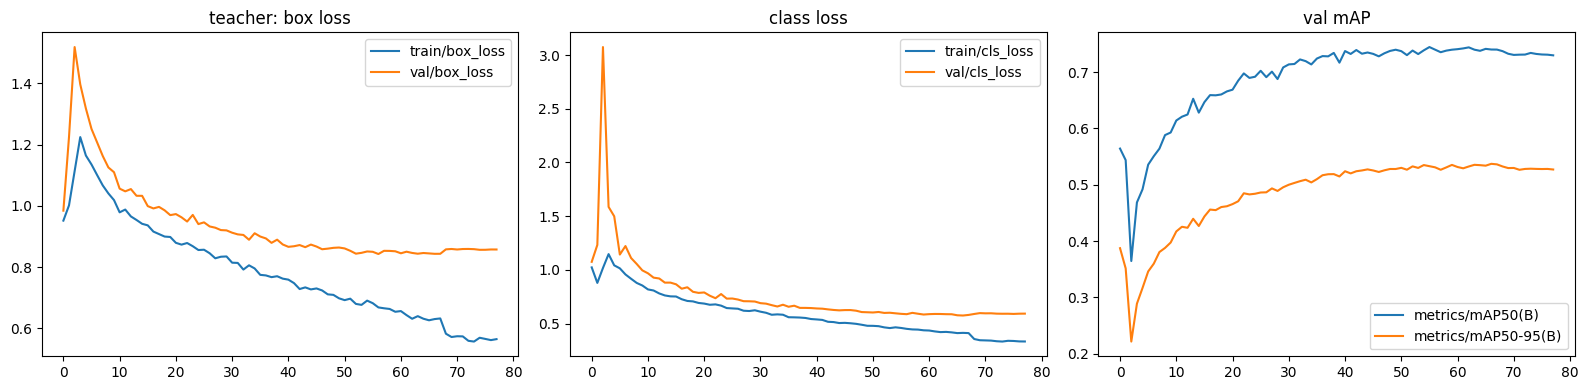

teacher: {'epochs': 78, 'best_epoch': 67, 'best_val_mAP50-95': 0.5372, 'stopped_by': 'time cap or last epoch', 'hours': 1.52} -> /kaggle/working/runs/teacher/weights/best.pt


,CPPE mAP50,CPPE mAP50-95,SH17 mAP50,SH17 mAP50-95,HardHat mAP50,HardHat mAP50-95
model,,,,,,
app: SH17 yolov8s,0.792,0.552,0.642,0.419,0.333,0.098
app: site-safety yolov8n,0.385,0.242,0.197,0.095,0.385,0.086
current app (both),0.793,0.536,0.577,0.362,0.394,0.090
v1 (CSS yolo11s),0.396,0.254,0.201,0.107,0.331,0.076
teacher (CPPE+SH17),0.907,0.733,0.663,0.438,0.344,0.081


In [9]:
def link(src, dst):
    if not dst.exists():
        try:
            os.link(src, dst)
        except OSError:
            shutil.copy(src, dst)

def write_dataset(name, train, val, with_pseudo):
    """Ultralytics dataset: hard links to the resized images + YOLO label files + train/val lists."""
    root = SCRATCH / name
    shutil.rmtree(root, ignore_errors=True)
    (root / "images").mkdir(parents=True); (root / "labels").mkdir()
    lists = {"train": [], "val": []}
    for split, rs in (("train", train), ("val", val)):
        for r in rs:
            lines = []
            for c, x1, y1, x2, y2 in r["boxes"] + (r["pseudo"] if with_pseudo else []):
                x1, y1, x2, y2 = max(0., x1), max(0., y1), min(1., x2), min(1., y2)
                if (x2 - x1) * r["w"] >= 2 and (y2 - y1) * r["h"] >= 2:
                    lines.append(f"{CID[c]} {(x1 + x2) / 2:.6f} {(y1 + y2) / 2:.6f} {x2 - x1:.6f} {y2 - y1:.6f}")
            for k in range(OVERSAMPLE.get(r["src"], 1) if split == "train" else 1):
                stem = Path(r["path"]).stem + (f"__r{k}" if k else "")
                link(r["path"], root / "images" / f"{stem}.jpg")
                (root / "labels" / f"{stem}.txt").write_text("\n".join(lines))
                lists[split].append(str(root / "images" / f"{stem}.jpg"))
    for split, paths in lists.items():
        (root / f"{split}.txt").write_text("\n".join(paths))
    y = root / "data.yaml"
    y.write_text(yaml.safe_dump({"path": str(root), "train": "train.txt", "val": "val.txt",
                                 "names": dict(enumerate(CLASSES))}, sort_keys=False))
    print(f"{name}: {len(lists['train'])} train / {len(lists['val'])} val images")
    return y

def curves(run_dir, title):
    csv = pd.read_csv(Path(run_dir) / "results.csv"); csv.columns = [c.strip() for c in csv.columns]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    csv[["train/box_loss", "val/box_loss"]].plot(ax=ax[0], title=f"{title}: box loss")
    csv[["train/cls_loss", "val/cls_loss"]].plot(ax=ax[1], title="class loss")
    csv[["metrics/mAP50(B)", "metrics/mAP50-95(B)"]].plot(ax=ax[2], title="val mAP")
    plt.tight_layout(); plt.savefig(RES / f"curves_{title}.png", dpi=80); plt.show()
    return len(csv)

TRAINING = {}
def train(name, data_yaml, start, hours):
    """Train until early stopping (PATIENCE epochs without a better validation mAP50-95) or the time cap,
    whichever comes first. Ultralytics keeps the best epoch as best.pt."""
    hours = max(round(hours, 2), 0.25)
    args = dict(data=str(data_yaml), imgsz=IMGSZ, seed=SEED, project=str(WORK / "runs"), name=name, exist_ok=True,
                patience=PATIENCE[name], cos_lr=True, close_mosaic=10, workers=WORKERS, plots=True, verbose=False)
    budget = lambda h: dict(epochs=1) if SMOKE else dict(epochs=300, time=h)   # `time` (hours) caps the run
    print(f"{name}: up to {hours} h on {DEVICE}, batch {BATCH}, early stopping after {PATIENCE[name]} epochs without progress")
    t0 = time.time()
    try:
        m = YOLO(str(start))
        m.train(device=DEVICE, batch=BATCH, **args, **budget(hours))
    except Exception as e:
        if not isinstance(DEVICE, list):
            raise
        left = max(round(hours - (time.time() - t0) / 3600, 2), 0.25)
        print(f"multi-GPU training failed ({e!r}); retrying on one GPU for {left} h")
        m = YOLO(str(start))
        m.train(device=0, batch=BATCH_PER_GPU, **args, **budget(left))
    run = Path(m.trainer.save_dir)
    n = curves(run, name)
    csv = pd.read_csv(run / "results.csv"); csv.columns = [c.strip() for c in csv.columns]
    k = int(csv["metrics/mAP50-95(B)"].idxmax())
    best_epoch = int(csv["epoch"].iloc[k]) if "epoch" in csv else k + 1
    TRAINING[name] = {"epochs": n, "best_epoch": best_epoch, "best_val_mAP50-95": round(float(csv["metrics/mAP50-95(B)"].iloc[k]), 4),
                      "stopped_by": "early stopping" if n - best_epoch >= PATIENCE[name] else "time cap or last epoch",
                      "hours": round((time.time() - t0) / 3600, 2)}
    print(f"{name}: {TRAINING[name]} -> {run / 'weights' / 'best.pt'}")
    return run / "weights" / "best.pt"

FULL = ("cppe", "sh17")
if TEACHER_WEIGHTS:
    TEACHER = Path(TEACHER_WEIGHTS)
else:
    t_yaml = write_dataset("teacher", [r for r in records if r["src"] in FULL and r["split"] == "train"],
                           [r for r in records if r["src"] in FULL and r["split"] == "val"], with_pseudo=False)
    # leave time for the final model (STUDENT_HOURS) and ~1 h of evaluation after it
    TEACHER = train("teacher", t_yaml, MODEL_PATH, min(TEACHER_HOURS, hours_left() - STUDENT_HOURS - 1.0))
teacher = YOLO(str(TEACHER))
evaluate("teacher (CPPE+SH17)", predict(teacher, TEST_PATHS))
display(overview().round(3))

## 5 · Pseudo-labels for the classes a dataset doesn't annotate
Only training images get them, and only for the classes their dataset leaves out (Hard Hat Workers: everything
but helmet; CSS: gloves, boots, goggles, earmuffs; Construction-PPE: mask, earmuffs). Dashed boxes below are
the teacher's.

,images,person,helmet,vest,gloves,boots,goggles,mask,earmuffs
source,,,,,,,,,
Construction Site Safety,2792,0,0,0,214,558,110,0,2
Construction-PPE,680,0,0,0,0,0,0,0,0
Hard Hat Workers,4154,13124,0,565,989,3672,287,53,2


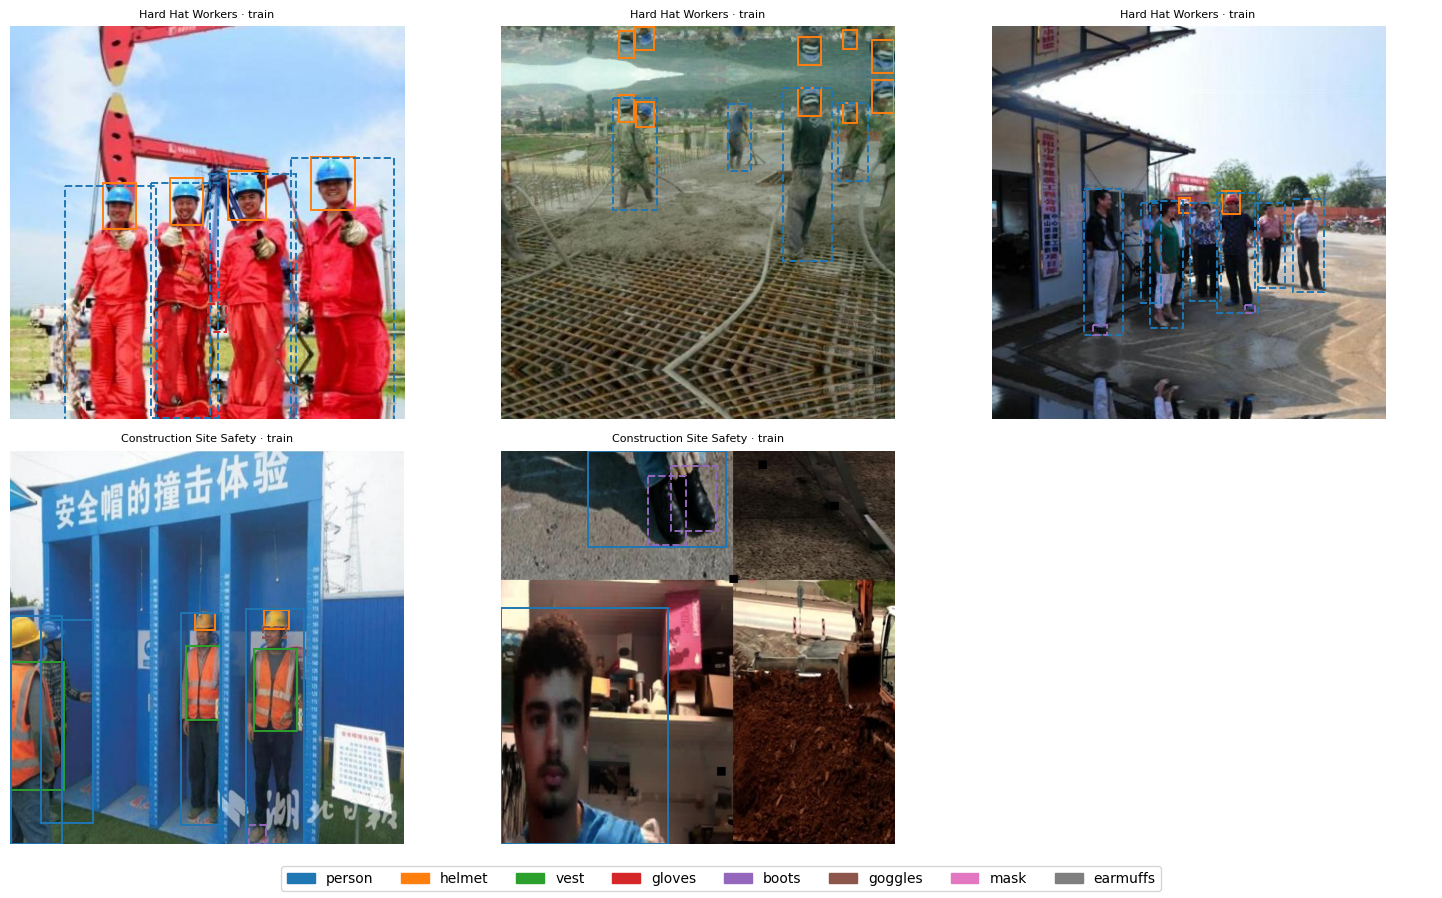

In [10]:
todo = [r for r in records if r["split"] == "train" and set(CLASSES) - LABELED[r["src"]]]
pl = predict(teacher, [r["path"] for r in todo], conf=PSEUDO_CONF)
for r in todo:
    miss = set(CLASSES) - LABELED[r["src"]]
    r["pseudo"] = [(c, x1 / r["w"], y1 / r["h"], x2 / r["w"], y2 / r["h"]) for c, s, x1, y1, x2, y2 in pl[r["path"]] if c in miss]
pseudo = pd.DataFrame([{"source": TITLES[r["src"]], "images": 1, **collections.Counter(b[0] for b in r["pseudo"])}
                       for r in todo]).groupby("source").sum().reindex(columns=["images"] + CLASSES).fillna(0).astype(int)
display(pseudo); pseudo.to_csv(RES / "pseudo_labels.csv")
gallery(pick([r for r in todo if r["pseudo"]], (("hardhat", 3), ("css", 2), ("cppe", 1)), 2), "pseudo_labels.png")

## 6 · Stage 2: the final model on every source
It starts from the teacher, trains on all training images (dataset labels + pseudo-labels), and is validated on
the fully labelled Construction-PPE + SH17 val images.

student: 14776 train / 802 val images
v2: up to 5.0 h on [0, 1], batch 32, early stopping after 30 epochs without progress
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/tmp/safesight/student/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, li

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/121      4.62G     0.9134     0.7247      1.082        115        640: 100% ━━━━━━━━━━━━ 462/462 3.5it/s 2:14
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.2it/s 3.1s
                   all        802       3497      0.819      0.638      0.701      0.496

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/126      4.63G     0.9508     0.7557      1.087        119        640: 100% ━━━━━━━━━━━━ 462/462 3.7it/s 2:05
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.2it/s 3.1s
                   all        802       3497      0.847       0.59      0.695       0.48

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/130      4.63G     0.9976      0.818      1.114        116        640: 100% ━━━━━━━━━━━

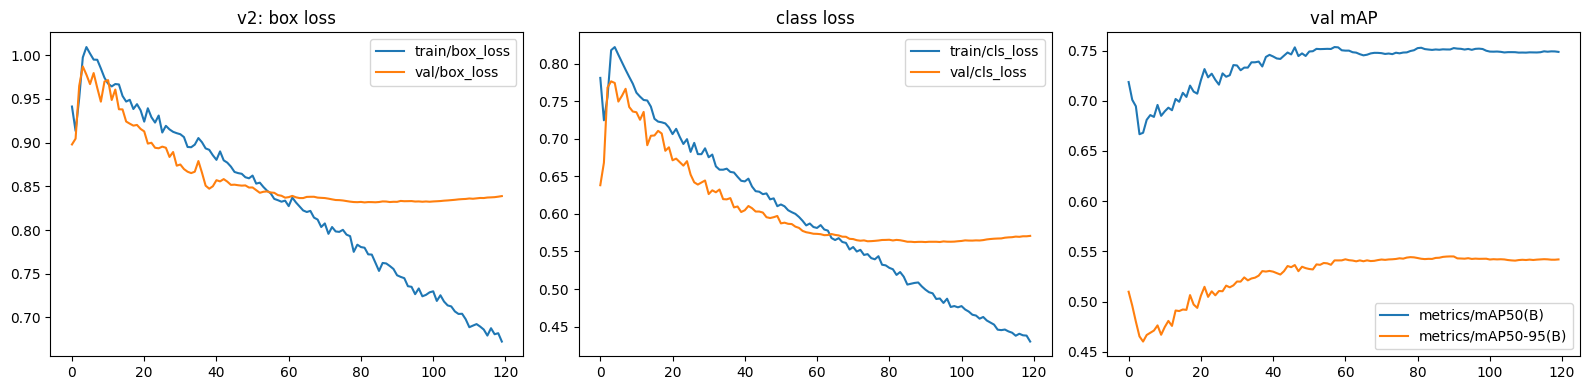

v2: {'epochs': 120, 'best_epoch': 90, 'best_val_mAP50-95': 0.5449, 'stopped_by': 'early stopping', 'hours': 4.32} -> /kaggle/working/runs/v2/weights/best.pt


In [11]:
s_yaml = write_dataset("student", [r for r in records if r["split"] == "train"],
                       [r for r in records if r["src"] in FULL and r["split"] == "val"], with_pseudo=True)
BEST = train("v2", s_yaml, TEACHER, min(STUDENT_HOURS, hours_left() - 1.0))   # ~1 h kept for evaluation
v2 = YOLO(str(BEST))
evaluate("v2", predict(v2, TEST_PATHS))
evaluate("current app + v2", merge(PRED["current app (both)"], PRED["v2"]))

## 7 · Confidence threshold, chosen on the validation images
The app drops detections below a model's confidence threshold (0.35 by default). This picks the threshold with
the best F1 (averaged over classes, IoU ≥ 0.5) on the validation images: never on the test sets, so the test
results stay honest. Use it when registering the model in the app.

,mean F1,F1 person,F1 helmet,F1 vest,F1 gloves,F1 boots,F1 goggles,F1 mask,F1 earmuffs
conf,,,,,,,,,
0.10,0.712,0.860,0.781,0.845,0.641,0.667,0.741,0.628,0.533
0.15,0.740,0.878,0.805,0.857,0.688,0.703,0.766,0.661,0.561
0.20,0.754,0.887,0.825,0.857,0.714,0.729,0.780,0.685,0.556
0.25,0.758,0.896,0.836,0.863,0.725,0.747,0.796,0.673,0.528
0.30,0.766,0.900,0.844,0.862,0.738,0.759,0.805,0.692,0.528
0.35,0.760,0.903,0.844,0.857,0.726,0.771,0.807,0.692,0.480
0.40,0.760,0.904,0.851,0.858,0.726,0.771,0.802,0.680,0.490
0.45,0.762,0.904,0.858,0.858,0.722,0.760,0.812,0.686,0.500
0.50,0.764,0.902,0.862,0.852,0.719,0.756,0.814,0.700,0.511


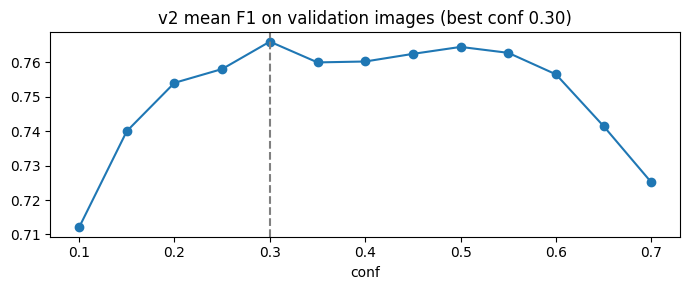

use confidence 0.30 for v2 in the app (default 0.35)


In [12]:
VAL = [r for r in records if r["src"] in FULL and r["split"] == "val"]
VAL_GT = {r["path"]: [(b[0], *box_px(r, b)) for b in r["boxes"]] for r in VAL}
VAL_CLS = {r["path"]: [c for c in CLASSES if c in LABELED[r["src"]]] for r in VAL}

def f1_table(preds, grid=np.round(np.arange(0.10, 0.71, 0.05), 2)):
    """Per-class precision/recall/F1 at each threshold. Detections are matched greedily by score, so the
    matches above a threshold are the same as in the full matching."""
    hits = collections.defaultdict(lambda: ([], [], [0]))   # class -> (scores of hits, scores of misses, [n_gt])
    for img, gt in VAL_GT.items():
        for c in VAL_CLS[img]:
            g = np.array([b[1:] for b in gt if b[0] == c], float).reshape(-1, 4)
            d = sorted((p for p in preds.get(img, []) if p[0] == c), key=lambda p: -p[1])
            tp_s, fp_s, n = hits[c]
            n[0] += len(g)
            iou = iou_matrix(g, np.array([p[2:] for p in d], float)) if len(g) and d else None
            used = np.zeros(len(g), bool)
            for j, p in enumerate(d):
                hit = False
                if iou is not None:
                    m = np.where(used, -1.0, iou[:, j]); i = int(m.argmax())
                    if m[i] >= 0.5:
                        used[i] = hit = True
                (tp_s if hit else fp_s).append(p[1])
    rows = []
    for t in grid:
        f1s = {}
        for c, (tp_s, fp_s, n) in hits.items():
            if n[0] == 0:
                continue
            tp, fp = sum(s >= t for s in tp_s), sum(s >= t for s in fp_s)
            p, r = tp / max(tp + fp, 1), tp / n[0]
            f1s[c] = 2 * p * r / max(p + r, 1e-9)
        rows.append({"conf": t, "mean F1": np.mean(list(f1s.values())) if f1s else 0.0, **{f"F1 {c}": v for c, v in f1s.items()}})
    return pd.DataFrame(rows).set_index("conf")

f1 = f1_table(predict(v2, list(VAL_GT), conf=0.05))
BEST_CONF = float(f1["mean F1"].idxmax())
display(f1.round(3)); f1.to_csv(RES / "confidence_threshold.csv")
ax = f1["mean F1"].plot(figsize=(7, 3), marker="o", title=f"v2 mean F1 on validation images (best conf {BEST_CONF:.2f})")
ax.axvline(BEST_CONF, ls="--", c="gray"); plt.tight_layout(); plt.savefig(RES / "confidence_threshold.png", dpi=80); plt.show()
print(f"use confidence {BEST_CONF:.2f} for v2 in the app (default 0.35)")

## 8 · Results on the frozen test sets
**CPPE** (Construction-PPE) is the headline: construction photos that none of the models has trained on.

,CPPE mAP50,CPPE mAP50-95,SH17 mAP50,SH17 mAP50-95,HardHat mAP50,HardHat mAP50-95
model,,,,,,
app: SH17 yolov8s,0.792,0.552,0.642,0.419,0.333,0.098
app: site-safety yolov8n,0.385,0.242,0.197,0.095,0.385,0.086
current app (both),0.793,0.536,0.577,0.362,0.394,0.090
v1 (CSS yolo11s),0.396,0.254,0.201,0.107,0.331,0.076
teacher (CPPE+SH17),0.907,0.733,0.663,0.438,0.344,0.081
v2,0.907,0.731,0.671,0.448,0.960,0.639
current app + v2,0.877,0.682,0.627,0.402,0.692,0.372



AP50 per class, Construction-PPE test set


,person,helmet,vest,gloves,boots,goggles
app: SH17 yolov8s,0.910,0.738,0.816,0.799,0.573,0.913
app: site-safety yolov8n,0.805,0.752,0.751,0.000,0.000,0.000
current app (both),0.894,0.757,0.822,0.799,0.573,0.913
v1 (CSS yolo11s),0.821,0.773,0.779,0.000,0.000,0.000
teacher (CPPE+SH17),0.961,0.889,0.955,0.871,0.800,0.965
v2,0.961,0.883,0.958,0.855,0.820,0.966
current app + v2,0.940,0.864,0.934,0.850,0.718,0.955



AP50 per class, SH17 test set


,person,helmet,vest,gloves,boots,goggles,mask,earmuffs
app: SH17 yolov8s,0.894,0.672,0.477,0.560,0.618,0.717,0.720,0.480
app: site-safety yolov8n,0.635,0.374,0.151,0.000,0.000,0.000,0.415,0.000
current app (both),0.861,0.473,0.282,0.560,0.618,0.717,0.628,0.480
v1 (CSS yolo11s),0.608,0.427,0.231,0.000,0.000,0.000,0.338,0.000
teacher (CPPE+SH17),0.903,0.749,0.549,0.524,0.614,0.755,0.728,0.482
v2,0.905,0.764,0.551,0.537,0.635,0.737,0.719,0.518
current app + v2,0.883,0.564,0.341,0.594,0.644,0.752,0.674,0.565



AP50 per class, Hard Hat Workers test set


,helmet
app: SH17 yolov8s,0.333
app: site-safety yolov8n,0.385
current app (both),0.394
v1 (CSS yolo11s),0.331
teacher (CPPE+SH17),0.344
v2,0.960
current app + v2,0.692


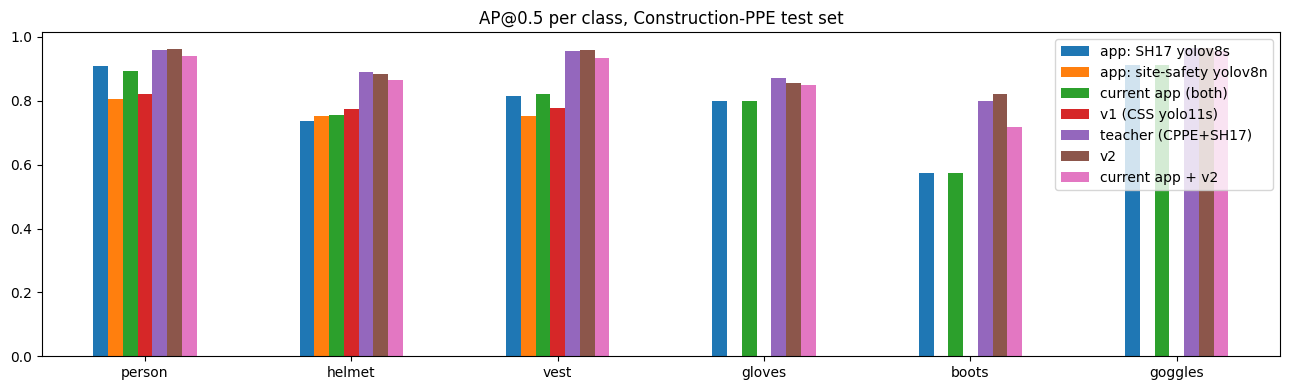

cppe_test: 0 train / 200 val images
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2962.3±246.6 MB/s, size: 284.7 KB)
val: Scanning /tmp/safesight/cppe_test/labels... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 1.2Kit/s 0.2s
val: New cache created: /tmp/safesight/cppe_test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.2it/s 3.1s
                   all        200       2116      0.937      0.849      0.897      0.707
Speed: 0.7ms preprocess, 7.8ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /kaggle/working/runs/v2_cppe_test
Ultralytics CPPE test: mAP50 = 0.897 | mAP50-95 = 0.707


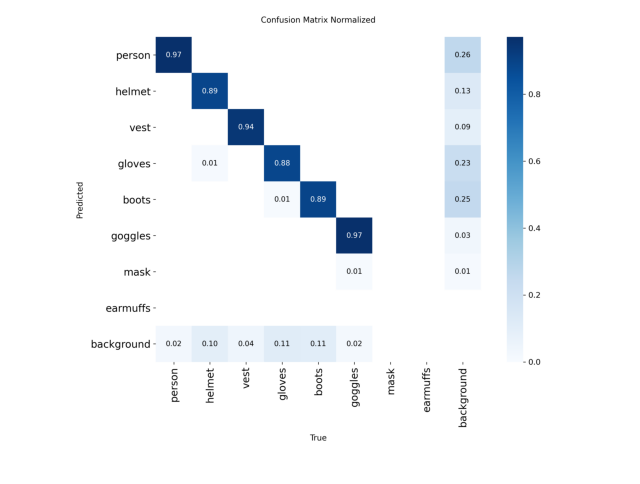

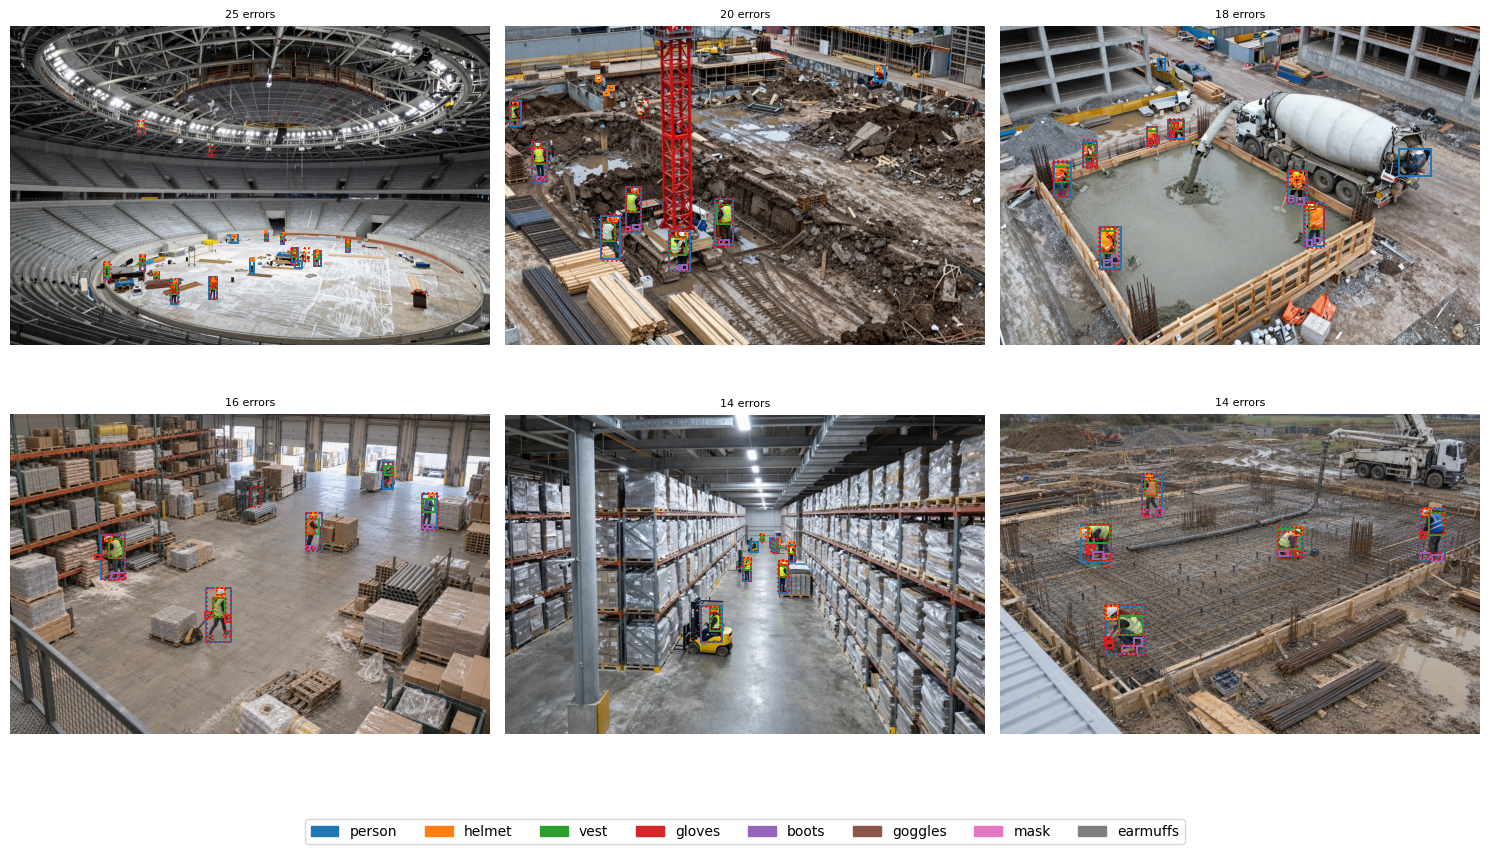

In [13]:
comparison = overview()
display(comparison.round(3)); comparison.to_csv(RES / "comparison.csv")
for s in TEST:
    print(f"\nAP50 per class, {TITLES[s]} test set")
    t = per_class(s); display(t.round(3)); t.to_csv(RES / f"ap50_per_class_{s}.csv")

t = per_class("cppe") if "cppe" in TEST else None
if t is not None:
    ax = t.T.plot.bar(figsize=(13, 4), title="AP@0.5 per class, Construction-PPE test set"); ax.set_xticklabels(t.columns, rotation=0)
    plt.tight_layout(); plt.savefig(RES / "ap50_cppe.png", dpi=80); plt.show()

    # Ultralytics' own confusion matrix on the same test images (Construction-PPE has no mask/earmuff labels)
    c_yaml = write_dataset("cppe_test", [], TEST["cppe"], with_pseudo=False)
    metrics = v2.val(data=str(c_yaml), split="val", imgsz=IMGSZ, device=PRED_DEVICE, project=str(WORK / "runs"),
                     name="v2_cppe_test", exist_ok=True, plots=True, verbose=False)
    print(f"Ultralytics CPPE test: mAP50 = {metrics.box.map50:.3f} | mAP50-95 = {metrics.box.map:.3f}")
    cm = Path(metrics.save_dir) / "confusion_matrix_normalized.png"
    if cm.exists():
        plt.figure(figsize=(8, 7)); plt.imshow(Image.open(cm)); plt.axis("off"); plt.show()

    # failure gallery: the Construction-PPE test images with the most missed + wrong boxes (conf >= 0.35)
    def n_errors(r):
        gt = TEST_GT["cppe"][r["path"]]
        d = [x for x in PRED["v2"][r["path"]] if x[1] >= 0.35 and x[0] in TEST_CLASSES["cppe"]]
        used, fp = set(), 0
        for c, s, *b in d:
            ok = [i for i, (gc, *gb) in enumerate(gt) if gc == c and i not in used
                  and iou_matrix(np.array([b]), np.array([gb]))[0, 0] >= 0.5]
            if ok:
                used.add(ok[0])
            else:
                fp += 1
        return len(gt) - len(used) + fp, d
    worst = sorted(TEST["cppe"], key=lambda r: -n_errors(r)[0])[:6]
    gallery(worst, "failures_cppe.png", [f"{n_errors(r)[0]} errors" for r in worst], [n_errors(r)[1] for r in worst])

## 9 · Export to ONNX (what the app runs), parity and CPU speed

In [14]:
FINAL = WORK / f"safesight_v2_{Path(MODEL).stem}.onnx"
shutil.copy(v2.export(format="onnx", imgsz=IMGSZ, opset=17, simplify=True, dynamic=False), FINAL)
size_mb = FINAL.stat().st_size / 1e6
print(f"{FINAL.name}: {size_mb:.1f} MB", "OK for the app (<= 50 MB)" if size_mb <= 50 else "TOO BIG: use a smaller model")

chk = TEST_PATHS[:20]
a = predict(v2, chk, conf=0.35); b = predict(YOLO(str(FINAL), task="detect"), chk, conf=0.35, device="cpu")
hits = sum(any(c2 == c and iou_matrix(np.array([bx]), np.array([bx2]))[0, 0] >= 0.85 for c2, s2, *bx2 in b[p])
           for p in chk for c, s, *bx in a[p])
print(f"ONNX reproduces {hits}/{sum(len(a[p]) for p in chk)} PyTorch detections")
if APP is not None:   # the app's own ONNX runner (ppe_core), which is what will run this model in production
    sys.path.insert(0, str(APP))
    from ppe_core.models import OnnxYolo
    runner = OnnxYolo(str(FINAL))
    app_hits = 0
    for p in chk:
        # same NMS IoU (0.6) as the PyTorch predictions above, so only the runtime is compared
        boxes, scores, cls, _ = runner.predict(np.asarray(Image.open(p).convert("RGB")), 0.35, 0.6)
        got = [(runner.names[int(k)], bb) for bb, k in zip(boxes, cls)]
        app_hits += sum(any(gc == c and iou_matrix(np.array([bx]), np.array([gb]))[0, 0] >= 0.85 for gc, gb in got)
                        for c, s, *bx in a[p])
    print(f"the app's ONNX runner reproduces {app_hits}/{sum(len(a[p]) for p in chk)} PyTorch detections "
          f"({'NMS-free' if runner.end2end else 'NMS'} head)")

import onnxruntime as ort
sess = ort.InferenceSession(str(FINAL), providers=["CPUExecutionProvider"])
x = np.random.rand(1, 3, IMGSZ, IMGSZ).astype(np.float32); inp = sess.get_inputs()[0].name
sess.run(None, {inp: x}); t0 = time.time()
for _ in range(10):
    sess.run(None, {inp: x})
cpu_ms = (time.time() - t0) / 10 * 1000
print(f"CPU inference: {cpu_ms:.0f} ms / image")

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs

PyTorch: starting from '/kaggle/working/runs/v2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 12, 8400) (18.3 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.5s, saved as '/kaggle/working/runs/v2/weights/best.onnx' (36.2 MB)

Export complete (3.0s)
Results saved to /kaggle/working/runs/v2/weights/best.onnx
Predict:         yolo predict task=detect model=/kaggle/working/runs/v2/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/kaggle/working/runs/v2/weights/best.onnx imgsz=640 data=/tmp/safesight/student/data.yaml 
Visualize:       https://netron.app
s

## 10 · Per-worker accuracy with the app's own pipeline
This is the decision the app actually makes: *is worker #2 wearing a helmet?* For every labelled worker in the
Construction-PPE test set, the ground truth comes from that dataset's boxes. An item is **worn** if its box sits
inside the worker, and **absent** if a `no_helmet`/`no_vest`/… box does (for gloves and boots, one bare hand or foot
already counts as absent). Workers under 48 px are left out, because the app reports them as *unknown*.

* **found**: share of labelled workers the app finds (person IoU ≥ 0.5).
* **accuracy**: correct worn/absent calls, among workers it found and decided on (not unknown).
* **violation precision / recall**: for "absent". Recall counts an *unknown* as a missed violation.
* **unknown**: share of found workers sent to the review queue.
* **helmet+vest verdict**: the default site policy, i.e. compliant vs. violation per worker.

In [15]:
ITEMS, PAIRED = ["helmet", "vest", "gloves", "boots", "goggles"], {"gloves", "boots"}
workers = None
if APP is None or len(APP_MODELS) < len(APP_FILES) or "cppe" not in TEST:
    print("skipped: needs the safesight-app input (ppe_core + models) and the Construction-PPE test set")
else:
    sys.path.insert(0, str(APP))
    from ppe_core.config import AppConfig, AssociationConfig, DetectorConfig, PoseConfig
    from ppe_core.pipeline import Pipeline
    MIN_H = AssociationConfig().min_person_height
    pose_cfg = PoseConfig(weights=str(APP_MODELS["yolo11n-pose.onnx"]))
    app_dets = [DetectorConfig("construction-safety-yolov8n", str(APP_MODELS["construction-safety-yolov8n.onnx"])),
                DetectorConfig("sh17-yolov8s", str(APP_MODELS["yolo8s.onnx"]))]
    CONFIGS = {"current app": app_dets, "v2": [DetectorConfig("safesight-v2", str(FINAL), conf=BEST_CONF)],
               "current app + v2": app_dets + [DetectorConfig("safesight-v2", str(FINAL), conf=BEST_CONF)]}
    if V1_ONNX:
        CONFIGS["v1 (CSS)"] = [DetectorConfig("v1-css", str(V1_ONNX))]

    def worker_truth(r):
        W, H = r["w"], r["h"]
        persons = [np.array(box_px(r, b)) for b in r["boxes"] if b[0] == "person"]
        marks = [collections.defaultdict(set) for _ in persons]
        if persons:
            P = np.array(persons)
            area = (P[:, 2] - P[:, 0]) * (P[:, 3] - P[:, 1])
            for kind, boxes in (("pos", r["boxes"]), ("neg", r["neg"])):
                for b in boxes:
                    if b[0] not in ITEMS:
                        continue
                    x1, y1, x2, y2 = box_px(r, b)
                    ix = np.clip(np.minimum(x2, P[:, 2]) - np.maximum(x1, P[:, 0]), 0, None)
                    iy = np.clip(np.minimum(y2, P[:, 3]) - np.maximum(y1, P[:, 1]), 0, None)
                    ioa = ix * iy / max((x2 - x1) * (y2 - y1), 1e-9)
                    j = int(np.lexsort((area, -ioa))[0])   # the worker that contains it most; the smaller one on ties
                    if ioa[j] >= 0.5:
                        marks[j][b[0]].add(kind)
        truth = [{c: (("absent" if "neg" in k else "worn") if c in PAIRED else ("worn" if "pos" in k else "absent"))
                  for c, k in m.items()} for m in marks]
        return persons, truth

    def iou1(a, b):
        return iou_matrix(np.array([a]), np.array([b]))[0, 0]

    rows = []
    for name, dets in CONFIGS.items():
        pipe = Pipeline(AppConfig(detectors=dets, pose=pose_cfg, association=AssociationConfig(), default_required=ITEMS))
        st = {i: collections.Counter() for i in ITEMS + ["helmet+vest verdict"]}
        for r in TEST["cppe"]:
            persons, truth = worker_truth(r)
            keep = [k for k, p in enumerate(persons) if p[3] - p[1] >= MIN_H and truth[k]]
            if not keep:
                continue
            out = pipe.run(np.asarray(Image.open(r["path"]).convert("RGB")), ITEMS)
            pboxes = [np.array([a.person.box.x1, a.person.box.y1, a.person.box.x2, a.person.box.y2]) for a in out.assessments]
            pairs = sorted(((iou1(persons[k], pb), k, j) for k in keep for j, pb in enumerate(pboxes)), key=lambda x: -x[0])
            match, used = {}, set()
            for v, k, j in pairs:
                if v >= 0.5 and k not in match and j not in used:
                    match[k] = j; used.add(j)
            for k in keep:
                t = dict(truth[k])
                if "helmet" in t and "vest" in t:
                    t["helmet+vest verdict"] = "absent" if "absent" in (t["helmet"], t["vest"]) else "worn"
                states = {i: out.assessments[match[k]].items[i].state for i in ITEMS} if k in match else {}
                if states:
                    hv = [states["helmet"], states["vest"]]
                    states["helmet+vest verdict"] = ("absent" if "absent" in hv else
                                                     "unknown" if {"unknown", "not_checked"} & set(hv) else "worn")
                for item, truth_state in t.items():
                    c = st[item]; c["labelled"] += 1; c["truth absent"] += truth_state == "absent"
                    if k not in match:
                        continue
                    s = states[item]; c["found"] += 1; c[s] += 1
                    if s in ("worn", "absent"):
                        c["decided"] += 1; c["correct"] += s == truth_state
                        c["tp"] += s == "absent" and truth_state == "absent"; c["fp"] += s == "absent" and truth_state == "worn"
                    c["found absent"] += truth_state == "absent"
        for item, c in st.items():
            rows.append({"config": name, "item": item, "workers": c["labelled"], "found": c["found"] / max(c["labelled"], 1),
                         "accuracy": c["correct"] / max(c["decided"], 1),
                         "violation precision": c["tp"] / max(c["tp"] + c["fp"], 1),
                         "violation recall": c["tp"] / max(c["found absent"], 1),
                         "unknown": c["unknown"] / max(c["found"], 1), "not checked": c["not_checked"] / max(c["found"], 1)})
    workers = pd.DataFrame(rows).set_index(["item", "config"]).sort_index()
    display(workers.round(3)); workers.to_csv(RES / "per_worker.csv")

workers  found  accuracy  \
item                config                                       
boots               current app           339  0.991     0.505   
                    current app + v2      339  0.997     0.586   
                    v1 (CSS)              339  0.971     0.000   
                    v2                    339  1.000     0.677   
gloves              current app           326  0.985     0.687   
                    current app + v2      326  0.988     0.798   
                    v1 (CSS)              326  0.945     0.000   
                    v2                    326  0.991     0.789   
goggles             current app           221  0.995     0.927   
                    current app + v2      221  0.995     0.955   
                    v1 (CSS)              221  0.995     0.000   
                    v2                    221  0.995     0.959   
helmet              current app           424  0.943     0.784   
                    current app + v2      424  0.969     0.868   
                    v1 (CSS)              424  0.908     0.833   
                    v2                    424  0.976     0.915   
helmet+vest verdict current app           420  0.948     0.775   
                    current app + v2      420  0.974     0.870   
                    v1 (CSS)              420  0.912     0.795   
                    v2                    420  0.983     0.903   
vest                current app           424  0.946     0.830   
                    current app + v2      424  0.972     0.944   
                    v1 (CSS)              424  0.910     0.844   
                    v2                    424  0.981     0.961   

                                      violation precision  violation recall  \
item                config                                                    
boots               current app                     0.268             0.489   
                    current app + v2                0.321             0.473   
                    v1 (CSS)                        0.000             0.000   
                    v2                              0.449             0.868   
gloves              current app                     0.539             0.983   
                    current app + v2                0.650             0.975   
                    v1 (CSS)                        0.000             0.000   
                    v2                              0.643             0.967   
goggles             current app                     0.849             0.975   
                    current app + v2                0.949             0.926   
                    v1 (CSS)                        0.000             0.000   
                    v2                              0.939             0.951   
helmet              current app                     0.643             0.848   
                    current app + v2                0.838             0.776   
                    v1 (CSS)                        0.736             0.813   
                    v2                              0.855             0.913   
helmet+vest verdict current app                     0.685             0.910   
                    current app + v2                0.867             0.839   
                    v1 (CSS)                        0.714             0.893   
                    v2                              0.866             0.926   
vest                current app                     0.596             0.897   
                    current app + v2                0.924             0.842   
                    v1 (CSS)                        0.605             1.000   
                    v2                              0.913             0.931   

                                      unknown  not checked  
item                config                                  
boots               current app         0.009          0.0  
                    current app + v2    0.006          0.0  
                    v1

## 11 · Summary and recommendation

In [16]:
cmp = overview()
key = "CPPE mAP50-95" if "CPPE mAP50-95" in cmp else cmp.columns[1]
verdict = (lambda n: float(workers.loc[("helmet+vest verdict", n), "accuracy"])) if workers is not None else (lambda n: float("nan"))
app, ours, both = "current app (both)", "v2", "current app + v2"
beats = lambda n, cfg: cmp.loc[n, key] > cmp.loc[app, key] and (workers is None or verdict(cfg) >= verdict("current app"))
if beats(ours, "v2"):
    advice = "v2 beats the current app on its own: Models -> Register -> Activate (replace)."
elif beats(both, "current app + v2"):
    advice = "v2 helps next to the current models: Models -> Register -> Add to ensemble."
else:
    advice = "v2 does not beat the current app: keep the current models and look at the failures before training again."

summary = {"variant": f"v2-{Path(MODEL).stem}", "smoke_run": SMOKE, "classes": CLASSES, "base_model": MODEL, "imgsz": IMGSZ, "gpus": N_GPU, "batch": BATCH, "training": TRAINING, "conf": BEST_CONF,
           "images": stats["images"].unstack(fill_value=0).to_dict(), "pseudo_labels": pseudo.sum().to_dict(),
           "test": cmp.round(4).to_dict(orient="index"),
           "per_worker": None if workers is None else workers.round(4).reset_index().to_dict(orient="records"),
           "onnx_file": FINAL.name, "onnx_mb": round(size_mb, 1), "cpu_ms": round(cpu_ms), "recommendation": advice}
(RES / "summary.json").write_text(json.dumps(summary, indent=2, default=str))

notes = (f"SafeSight v2 ({Path(MODEL).stem}, {IMGSZ}px). Trained on Construction-PPE + SH17 + Hard Hat Workers"
         f"{' + CSS' if USE_CSS else ''}, teacher pseudo-labels for classes a dataset does not annotate. "
         f"Frozen Construction-PPE test: mAP50 {cmp.loc[ours].get('CPPE mAP50', float('nan')):.3f} / mAP50-95 "
         f"{cmp.loc[ours].get('CPPE mAP50-95', float('nan')):.3f} (current app {cmp.loc[app].get('CPPE mAP50', float('nan')):.3f} / "
         f"{cmp.loc[app].get('CPPE mAP50-95', float('nan')):.3f}). "
         + (f"Helmet+vest verdict accuracy {verdict('v2'):.3f} (current app {verdict('current app'):.3f}). " if workers is not None else "")
         + f"Register with confidence {BEST_CONF:.2f}. License: CC BY-NC-SA 4.0 (trained on SH17).")
(RES / "model_notes.txt").write_text(notes)
display(cmp.round(3))
print("\n" + advice + "\n\nNotes for the Models page:\n" + notes)
print(f"\nDownload {FINAL.name} and results/ from the Output tab.")

,CPPE mAP50,CPPE mAP50-95,SH17 mAP50,SH17 mAP50-95,HardHat mAP50,HardHat mAP50-95
model,,,,,,
app: SH17 yolov8s,0.792,0.552,0.642,0.419,0.333,0.098
app: site-safety yolov8n,0.385,0.242,0.197,0.095,0.385,0.086
current app (both),0.793,0.536,0.577,0.362,0.394,0.090
v1 (CSS yolo11s),0.396,0.254,0.201,0.107,0.331,0.076
teacher (CPPE+SH17),0.907,0.733,0.663,0.438,0.344,0.081
v2,0.907,0.731,0.671,0.448,0.960,0.639
current app + v2,0.877,0.682,0.627,0.402,0.692,0.372



v2 beats the current app on its own: Models -> Register -> Activate (replace).

Notes for the Models page:
SafeSight v2 (yolo11s, 640px). Trained on Construction-PPE + SH17 + Hard Hat Workers + CSS, teacher pseudo-labels for classes a dataset does not annotate. Frozen Construction-PPE test: mAP50 0.907 / mAP50-95 0.731 (current app 0.793 / 0.536). Helmet+vest verdict accuracy 0.903 (current app 0.775). Register with confidence 0.30. License: CC BY-NC-SA 4.0 (trained on SH17).

Download safesight_v2_yolo11s.onnx and results/ from the Output tab.
